In [1]:
# ==============================================================================
# 📦 CELL 1: INSTALL REQUIRED PACKAGES (RUN FIRST ON COLAB / KAGGLE)
# ==============================================================================
try:
    get_ipython().system('pip install -q timm torchvision scikit-learn seaborn pandas opencv-python matplotlib tqdm')
    print("✅ Successfully installed dependencies via pip!")
except Exception:
    import sys, subprocess
    pkgs = ["timm", "torchvision", "scikit-learn", "seaborn", "pandas", "opencv-python", "matplotlib", "tqdm"]
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q"] + pkgs)
    print("✅ Successfully installed dependencies via subprocess!")


✅ Successfully installed dependencies via pip!


# 🚀 01-Improved. Multi-View Gated Attention Pooling Vision Baseline: ConvNeXt V2-Base

**Project:** Durian Ripeness Classification via Cross-Modal Knowledge Distillation (Durian Ripeness CMKD)  
**Model:** Multi-View ConvNeXt V2-Base (`convnextv2_base.fcmae_ft_in1k`) + $1024 \to 256$ Projection Block + Lightweight Gated Attention Pooling (Ilse et al.)  
**Checkpoint Path:** `/content/drive/MyDrive/durian-ripeness-cmkd/baselines/ConvNeXtV2/checkpoint`  
**Test Results Path:** `/content/drive/MyDrive/durian-ripeness-cmkd/baselines/ConvNeXtV2/results`

---

### 🌟 Key Architectural Improvements (Multi-View Fruit-Level Aggregation with ConvNeXt V2-Base):
1. **Fruit-Level Multi-View Grouping (`fruit_id`, e.g., `durian_002`):**
   - Gom tất cả các góc chụp thuộc về cùng một quả sầu riêng (cùng tiền tố định danh `durian_XXX`) thành một túi đa góc nhìn (**Multi-View Bag**) $\{I_1, I_2, \dots, I_N\}$ trước khi phân loại, bảo toàn sự phụ thuộc hình học giữa các góc chụp.
2. **FCMAE Feature Extraction & Dimensionality Compression ($1024 \to 256$):**
   - Cho từng góc nhìn $I_i$ đi qua **ConvNeXt V2-Base** (`convnextv2_base.fcmae_ft_in1k`, bỏ lớp `fc` cuối) để lấy vector đặc trưng $h_i \in \mathbb{R}^{1024}$, sau đó đưa ngay qua khối nén chiều:
     $$f_i = \text{Dropout}\Big(\text{GELU}\big(\text{LayerNorm}(\mathbf{W}_{proj} h_i)\big)\Big) \in \mathbb{R}^{256}$$
   - Giảm từ $1024$ xuống $256$ giúp giảm hơn $75\%$ tham số cho phần Attention phía sau, chống overfitting trên tập dữ liệu vừa phải và khớp trực tiếp với chiều embedding $256\text{-d}$ của nhánh Teacher trong CMKD.
3. **Lightweight Gated Attention Pooling (Ilse et al., $D = 128$):**
   - Tính trọng số đóng góp $a_i$ cho từng góc nhìn trên không gian $256\text{-d}$ đã nén (với chiều ẩn $D = 128$):
     $$a_i = \frac{\exp\Big(\mathbf{w}^T \big(\tanh(\mathbf{V} f_i) \odot \sigma(\mathbf{U} f_i)\big)\Big)}{\sum_{j=1}^{N} \exp\Big(\mathbf{w}^T \big(\tanh(\mathbf{V} f_j) \odot \sigma(\mathbf{U} f_j)\big)\Big)}, \quad F_{rgb} = \sum_{i=1}^{N} a_i f_i \in \mathbb{R}^{256}$$
4. **Anti-Overfitting, Drive Pretrained Weight Caching & Multi-View Regularization:**
   - **Drive Weight Caching:** Tự động lưu cache trọng số gốc `convnextv2_pretrained_raw_weights.pth` trong thư mục checkpoint để các lần chạy sau load tức thì và không bao giờ ghi đè lên các file checkpoint đã fine-tune.
   - **Random View Subsampling (View Dropout) + Delayed Feature-Space Mixup:** Lấy ngẫu nhiên tập con các góc nhìn của mỗi quả trong mỗi epoch kết hợp với Mixup trực tiếp trên không gian $F_{rgb} \in \mathbb{R}^{256}$ từ Epoch 11.
   - **Val Macro-F1 Best Checkpoint & Early Stopping:** Lưu checkpoint tốt nhất (`best_convnextv2_multiview.pth` và `convnextv2_multiview_backbone_256d.pth`) dựa trên **Fruit-level Validation Macro-F1**.

In [2]:
# 2. Import libraries and configure compute environment
import gc
import json
import math
import os
import random
import re
import sys
import time
import warnings
from collections import defaultdict
from pathlib import Path
from typing import Dict, List, Optional, Tuple

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import timm
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=UserWarning)

# Fix random seeds for Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Configure compute device (GPU / MPS / CPU)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu"))
print(f"✅ Active compute device: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"   • GPU Name: {torch.cuda.get_device_name(0)}")
    print(f"   • VRAM    : {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")


✅ Active compute device: cuda
   • GPU Name: NVIDIA L4
   • VRAM    : 22.03 GB


In [3]:
# 3. Mount Google Drive and configure Data, Checkpoint & Results paths
IN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")

def find_project_root() -> str:
    cur = os.path.abspath(".")
    for _ in range(6):
        if os.path.isdir(os.path.join(cur, "data")) or os.path.isdir(os.path.join(cur, "workspaces")):
            return cur
        parent = os.path.dirname(cur)
        if parent == cur:
            break
        cur = parent
    return os.path.abspath("../../..")

if IN_COLAB:
    from google.colab import drive
    if not os.path.exists("/content/drive/MyDrive"):
        drive.mount("/content/drive")
    print("✅ Successfully mounted Google Drive at /content/drive")
    
    DATA_SPLIT_DIR = "/content/drive/MyDrive/durian-ripeness-cmkd/data/split_data"
    DATA_FINAL_DIR = "/content/drive/MyDrive/durian-ripeness-cmkd/data/final"
    CHECKPOINT_DIR = "/content/drive/MyDrive/durian-ripeness-cmkd/baselines/ConvNeXtV2-improve/checkpoint"
    RESULTS_DIR = "/content/drive/MyDrive/durian-ripeness-cmkd/baselines/ConvNeXtV2-improve/results"
    DEMO_CACHE_DIR = "/content/colab_temp_cache/demo_vision_convnextv2_multiview"
else:
    PROJECT_ROOT = find_project_root()
    DATA_SPLIT_DIR = os.path.join(PROJECT_ROOT, "data", "split_data")
    DATA_FINAL_DIR = os.path.join(PROJECT_ROOT, "data", "final")
    CHECKPOINT_DIR = os.path.join(PROJECT_ROOT, "baselines", "ConvNeXtV2-improve", "outputs", "checkpoint")
    RESULTS_DIR = os.path.join(PROJECT_ROOT, "baselines", "ConvNeXtV2-improve", "outputs", "results")
    DEMO_CACHE_DIR = os.path.join(PROJECT_ROOT, ".demo_vision_cache")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

# Distinct checkpoint filenames so they never overwrite raw pretrained weights or single-view checkpoints
RAW_PRETRAINED_PATH = os.path.join(CHECKPOINT_DIR, "convnextv2_pretrained_raw_weights.pth")
BEST_CHECKPOINT_PATH = os.path.join(CHECKPOINT_DIR, "best_convnextv2_multiview.pth")
LAST_CHECKPOINT_PATH = os.path.join(CHECKPOINT_DIR, "last_convnextv2_multiview.pth")
BACKBONE_PROJ_PATH = os.path.join(CHECKPOINT_DIR, "convnextv2_multiview_backbone_256d.pth")

print(f"\n[PATH CONFIGURATION]")
print(f"  • Final Data Directory     : {DATA_FINAL_DIR}")
print(f"  • Checkpoint Directory     : {CHECKPOINT_DIR}")
print(f"  • Results Directory        : {RESULTS_DIR}")
print(f"  • Raw Pretrained Cache     : {RAW_PRETRAINED_PATH}")
print(f"  • Target Best Checkpoint   : {BEST_CHECKPOINT_PATH}")
print(f"  • 256-d Visual Extractor   : {BACKBONE_PROJ_PATH}")


Mounted at /content/drive
✅ Successfully mounted Google Drive at /content/drive

[PATH CONFIGURATION]
  • Final Data Directory     : /content/drive/MyDrive/durian-ripeness-cmkd/data/final
  • Checkpoint Directory     : /content/drive/MyDrive/durian-ripeness-cmkd/baselines/ConvNeXtV2-improve/checkpoint
  • Results Directory        : /content/drive/MyDrive/durian-ripeness-cmkd/baselines/ConvNeXtV2-improve/results
  • Raw Pretrained Cache     : /content/drive/MyDrive/durian-ripeness-cmkd/baselines/ConvNeXtV2-improve/checkpoint/convnextv2_pretrained_raw_weights.pth
  • Target Best Checkpoint   : /content/drive/MyDrive/durian-ripeness-cmkd/baselines/ConvNeXtV2-improve/checkpoint/best_convnextv2_multiview.pth
  • 256-d Visual Extractor   : /content/drive/MyDrive/durian-ripeness-cmkd/baselines/ConvNeXtV2-improve/checkpoint/convnextv2_multiview_backbone_256d.pth


In [4]:
# 4. Scan dataset splits, group images by Fruit ID (e.g., 'durian_002'), and compute Fruit-Level Class Weights
RIPENESS_ORDER = ["Unripe", "Ripe", "Overripe"]
LABEL_TO_IDX = {name: idx for idx, name in enumerate(RIPENESS_ORDER)}
IDX_TO_LABEL = {idx: name for name, idx in LABEL_TO_IDX.items()}

def parse_label_from_filename(filename: str) -> Optional[str]:
    fn = filename.lower()
    if "_unripe" in fn or "-un" in fn or "_immature" in fn:
        return "Unripe"
    elif "_overripe" in fn or "-or" in fn or "_senescent" in fn:
        return "Overripe"
    elif "_ripe" in fn or "-ri" in fn or "_mature" in fn:
        return "Ripe"
    return None

def extract_fruit_id(filename: str) -> str:
    """
    Extract the unique fruit identifier prefix from a filename (e.g., 'durian_002_A_Ripe_TOP.jpg' -> 'durian_002').
    Handles patterns like 'durian_002', 'durian-002', or general '<prefix>_<number>'.
    """
    stem = os.path.splitext(filename)[0]
    match = re.match(r"^([a-zA-Z]+[_\-]\d+)", stem)
    if match:
        return match.group(1).lower().replace("-", "_")
    parts = stem.split("_")
    if len(parts) >= 2:
        return f"{parts[0].lower()}_{parts[1].lower()}"
    return stem.lower()

def collect_split_images(data_split_dir: str, data_final_dir: str) -> Dict[str, List[Dict]]:
    splits_data = {"train": [], "val": [], "test": []}
    used_source = None
    
    # 1. Scan from data/final/
    if os.path.isdir(data_final_dir):
        for sp in ["train", "val", "test"]:
            actual_sp_dir = os.path.join(data_final_dir, "valid" if (sp == "val" and not os.path.isdir(os.path.join(data_final_dir, "val"))) else sp, "rgb")
            if os.path.isdir(actual_sp_dir):
                files = sorted([f for f in os.listdir(actual_sp_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])
                for f in files:
                    lbl = parse_label_from_filename(f)
                    if lbl:
                        splits_data[sp].append({
                            "filepath": os.path.join(actual_sp_dir, f),
                            "filename": f,
                            "fruit_id": extract_fruit_id(f),
                            "label": lbl,
                            "label_idx": LABEL_TO_IDX[lbl],
                            "split": sp
                        })
        if sum(len(v) for v in splits_data.values()) > 0:
            used_source = "data/final"

    # 2. Scan from data/split_data/
    if sum(len(v) for v in splits_data.values()) == 0 and os.path.isdir(data_split_dir):
        for sp in ["train", "val", "test"]:
            sp_dir = os.path.join(data_split_dir, sp, "dataset_clean_rgb")
            if os.path.isdir(sp_dir):
                files = sorted([f for f in os.listdir(sp_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])
                for f in files:
                    lbl = parse_label_from_filename(f)
                    if lbl:
                        splits_data[sp].append({
                            "filepath": os.path.join(sp_dir, f),
                            "filename": f,
                            "fruit_id": extract_fruit_id(f),
                            "label": lbl,
                            "label_idx": LABEL_TO_IDX[lbl],
                            "split": sp
                        })
        if sum(len(v) for v in splits_data.values()) > 0:
            used_source = "data/split_data"

    print(f"[*] Detected data source: {used_source or 'No real images found yet'}")
    return splits_data

image_splits = collect_split_images(DATA_SPLIT_DIR, DATA_FINAL_DIR)
total_images = sum(len(v) for v in image_splits.values())

# Fallback demo cache if environment is empty
if total_images == 0:
    print(f"⚠️ Creating synthetic multi-view demo image set at {DEMO_CACHE_DIR}...")
    os.makedirs(DEMO_CACHE_DIR, exist_ok=True)
    for sp, num_fruits in [("train", 9), ("val", 3), ("test", 3)]:
        sp_dir = os.path.join(DEMO_CACHE_DIR, sp)
        os.makedirs(sp_dir, exist_ok=True)
        for f_idx in range(num_fruits):
            lbl = RIPENESS_ORDER[f_idx % 3]
            fid = f"durian_{f_idx+1:03d}"
            for v_idx, angle in enumerate(["TOP", "SIDE1", "SIDE2", "BOTTOM"]):
                fname = f"{fid}_view{v_idx+1}_{lbl}_{angle}.jpg"
                fpath = os.path.join(sp_dir, fname)
                if not os.path.exists(fpath):
                    arr = np.random.randint(40, 180, (384, 384, 3), dtype=np.uint8)
                    cv2.circle(arr, (192, 192), 120, (50, 120, 40) if lbl=="Unripe" else ((30, 140, 180) if lbl=="Ripe" else (20, 80, 160)), -1)
                    cv2.imwrite(fpath, arr)
                image_splits[sp].append({
                    "filepath": fpath,
                    "filename": fname,
                    "fruit_id": fid,
                    "label": lbl,
                    "label_idx": LABEL_TO_IDX[lbl],
                    "split": sp
                })

# Group individual image records into Multi-View Fruit Bags by fruit_id
def group_images_by_fruit(records: List[Dict]) -> List[Dict]:
    grouped = defaultdict(list)
    for r in records:
        grouped[r["fruit_id"]].append(r)
    
    fruit_bags = []
    for fid in sorted(grouped.keys()):
        views = sorted(grouped[fid], key=lambda x: x["filename"])
        labels = [v["label"] for v in views]
        maj_label = max(set(labels), key=labels.count)
        fruit_bags.append({
            "fruit_id": fid,
            "label": maj_label,
            "label_idx": LABEL_TO_IDX[maj_label],
            "num_views": len(views),
            "views": views,
            "filepaths": [v["filepath"] for v in views],
            "filenames": [v["filename"] for v in views],
            "split": views[0]["split"]
        })
    return fruit_bags

fruit_splits = {sp: group_images_by_fruit(image_splits[sp]) for sp in ["train", "val", "test"]}

# Display both Image-level and Fruit-level distribution across splits
summary_records = []
for sp in ["train", "val", "test"]:
    df_img = pd.DataFrame(image_splits[sp])
    df_frt = pd.DataFrame(fruit_splits[sp])
    if len(df_frt) > 0:
        f_counts = df_frt["label"].value_counts().to_dict()
        avg_views = df_frt["num_views"].mean()
        min_views = df_frt["num_views"].min()
        max_views = df_frt["num_views"].max()
        summary_records.append({
            "Split": sp,
            "Fruits (Unripe/Ripe/Overripe)": f"{f_counts.get('Unripe',0)} / {f_counts.get('Ripe',0)} / {f_counts.get('Overripe',0)}",
            "Total Fruits": len(df_frt),
            "Total Images": len(df_img),
            "Views/Fruit (Min/Avg/Max)": f"{min_views} / {avg_views:.1f} / {max_views}"
        })
df_summary = pd.DataFrame(summary_records)
print(f"\n📊 [MULTI-VIEW FRUIT & IMAGE DISTRIBUTION ACROSS SPLITS]")
print(df_summary.to_string(index=False))

# --- COMPUTE CLASS WEIGHTS FROM TRAIN SPLIT ---
df_train_fruits = pd.DataFrame(fruit_splits["train"])
train_fruit_counts = [df_train_fruits["label"].value_counts().get(c, 1) for c in RIPENESS_ORDER]
total_train_fruits = sum(train_fruit_counts)

# Inverse class-frequency weighting formula: w_c = N / (K * N_c)
class_weights_val = [total_train_fruits / (len(RIPENESS_ORDER) * count) for count in train_fruit_counts]
CLASS_WEIGHTS = torch.tensor(class_weights_val, dtype=torch.float).to(DEVICE)

print(f"\n⚖️ [FRUIT-LEVEL CLASS WEIGHTS TO HANDLE IMBALANCE]")
for name, count, w in zip(RIPENESS_ORDER, train_fruit_counts, class_weights_val):
    print(f"  • {name:<9}: {count:>4} fruits -->  Weight: {w:.3f}")


[*] Detected data source: data/final

📊 [MULTI-VIEW FRUIT & IMAGE DISTRIBUTION ACROSS SPLITS]
Split Fruits (Unripe/Ripe/Overripe)  Total Fruits  Total Images Views/Fruit (Min/Avg/Max)
train                  39 / 41 / 44           124          1497             6 / 12.1 / 24
  val                     7 / 8 / 9            24           282             6 / 11.8 / 18
 test                     8 / 8 / 8            24           298             6 / 12.4 / 18

⚖️ [FRUIT-LEVEL CLASS WEIGHTS TO HANDLE IMBALANCE]
  • Unripe   :   39 fruits -->  Weight: 1.060
  • Ripe     :   41 fruits -->  Weight: 1.008
  • Overripe :   44 fruits -->  Weight: 0.939


In [5]:
# 5. High-resolution 384x384 preprocessing, L-channel CLAHE & Feature-Space Mixup
class CLAHETransform:
    """Apply standard CLAHE on the L (LAB) channel to enhance spine-groove micro-textures."""
    def __init__(self, clip_limit: float = 2.0, tile_grid_size: Tuple[int, int] = (8, 8)):
        self.clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid_size)

    def __call__(self, img: Image.Image) -> Image.Image:
        np_img = np.array(img)
        lab = cv2.cvtColor(np_img, cv2.COLOR_RGB2LAB)
        l, a, b = cv2.split(lab)
        l_clahe = self.clahe.apply(l)
        enhanced_lab = cv2.merge((l_clahe, a, b))
        enhanced_rgb = cv2.cvtColor(enhanced_lab, cv2.COLOR_LAB2RGB)
        return Image.fromarray(enhanced_rgb)

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# HIGH-RESOLUTION 384x384 INPUT TO CAPTURE FINE SPINE GROOVES
IMAGE_SIZE = 384

def get_train_transforms(image_size: int = IMAGE_SIZE) -> transforms.Compose:
    return transforms.Compose([
        CLAHETransform(clip_limit=2.0, tile_grid_size=(8, 8)),
        transforms.RandomResizedCrop(image_size, scale=(0.82, 1.0), ratio=(0.92, 1.08)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomVerticalFlip(p=0.2),
        transforms.RandomRotation(degrees=15),
        transforms.ColorJitter(brightness=0.12, contrast=0.12, saturation=0.12),
        transforms.ToTensor(),
        transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
        transforms.RandomErasing(p=0.15, scale=(0.02, 0.12), ratio=(0.3, 3.3), value='random')
    ])

def get_eval_transforms(image_size: int = IMAGE_SIZE) -> transforms.Compose:
    return transforms.Compose([
        CLAHETransform(clip_limit=2.0, tile_grid_size=(8, 8)),
        transforms.Resize(int(image_size * 1.08)),
        transforms.CenterCrop(image_size),
        transforms.ToTensor(),
        transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
    ])

def apply_feature_mixup(
    bag_embeddings: torch.Tensor,
    labels: torch.Tensor,
    alpha: float = 0.2
) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor, float]:
    """Mixup directly on aggregated 256-d fruit embeddings F_rgb to smooth fruit-level decision boundaries."""
    lam = float(np.random.beta(alpha, alpha)) if alpha > 0 else 1.0
    batch_size = bag_embeddings.size(0)
    index = torch.randperm(batch_size, device=bag_embeddings.device)
    mixed_embeddings = lam * bag_embeddings + (1.0 - lam) * bag_embeddings[index]
    return mixed_embeddings, labels, labels[index], lam


In [6]:
# 6. Multi-View Fruit Dataset & Variable-Length Bag Collate DataLoaders
class MultiViewDurianDataset(Dataset):
    """
    Each item is a Multi-View Bag of images belonging to the same fruit (e.g., 'durian_002').
    During training:
      - Randomly subsamples between `min_train_views` and `max_train_views` views per fruit per epoch.
      - Prevents the Gated Attention module from memorizing fixed view combinations while keeping
        VRAM consumption safe for ConvNeXtV2-Base (87.7M params) at 384x384 resolution.
    During evaluation (Val / Test):
      - Loads ALL available views of the fruit (up to `max_eval_views`) so Gated Attention pools every angle.
    """
    def __init__(
        self,
        fruit_bags: List[Dict],
        transform: Optional[transforms.Compose] = None,
        is_train: bool = True,
        min_train_views: int = 4,
        max_train_views: int = 6,
        max_eval_views: int = 24
    ):
        self.fruit_bags = fruit_bags
        self.transform = transform
        self.is_train = is_train
        self.min_train_views = min_train_views
        self.max_train_views = max_train_views
        self.max_eval_views = max_eval_views

    def __len__(self) -> int:
        return len(self.fruit_bags)

    def __getitem__(self, idx: int) -> Dict:
        bag = self.fruit_bags[idx]
        views = bag["views"]
        total_v = len(views)

        if self.is_train:
            low_k = min(total_v, self.min_train_views)
            high_k = min(total_v, self.max_train_views)
            k = random.randint(low_k, high_k) if high_k > low_k else high_k
            selected_views = random.sample(views, k)
        else:
            selected_views = views[:self.max_eval_views]

        tensors = []
        filenames = []
        for v in selected_views:
            with Image.open(v["filepath"]) as img:
                rgb_img = img.convert("RGB")
            tensor_img = self.transform(rgb_img) if self.transform else transforms.ToTensor()(rgb_img)
            tensors.append(tensor_img)
            filenames.append(v["filename"])

        views_tensor = torch.stack(tensors, dim=0)  # [N_i, 3, H, W]
        return {
            "views": views_tensor,
            "label_idx": bag["label_idx"],
            "fruit_id": bag["fruit_id"],
            "filenames": filenames,
            "num_views": len(tensors)
        }

def multiview_collate_fn(batch: List[Dict]) -> Dict:
    """
    Collates a batch of variable-length multi-view fruit bags into:
      - flat_images: Tensor [sum(N_i), 3, H, W] for single-pass ConvNeXtV2-Base execution
      - view_counts: List[int] = [N_1, N_2, ..., N_B] to split features back per fruit
      - labels     : Tensor [B] fruit-level ground-truth class indices
      - fruit_ids  : List[str] of length B
      - filenames  : List[List[str]] of length B
    """
    flat_images = torch.cat([item["views"] for item in batch], dim=0)
    view_counts = [item["num_views"] for item in batch]
    labels = torch.tensor([item["label_idx"] for item in batch], dtype=torch.long)
    fruit_ids = [item["fruit_id"] for item in batch]
    filenames = [item["filenames"] for item in batch]
    return {
        "flat_images": flat_images,
        "view_counts": view_counts,
        "labels": labels,
        "fruit_ids": fruit_ids,
        "filenames": filenames
    }

# ConvNeXtV2-Base has 87.7M params: FRUIT_BATCH_SIZE = 3 fruits (~15-18 views of 384x384 per pass) fits comfortably in Colab GPU VRAM
FRUIT_BATCH_SIZE = 3 if torch.cuda.is_available() else 1
EVAL_FRUIT_BATCH_SIZE = 2 if torch.cuda.is_available() else 1
# NUM_WORKERS = 2 + persistent_workers = True prevents Python 3.13 Colab _MultiProcessingDataLoaderIter.__del__ AssertionError
NUM_WORKERS = 2 if torch.cuda.is_available() else 0

train_dataset = MultiViewDurianDataset(
    fruit_splits["train"],
    transform=get_train_transforms(IMAGE_SIZE),
    is_train=True,
    min_train_views=4,
    max_train_views=6
)
val_dataset = MultiViewDurianDataset(
    fruit_splits["val"],
    transform=get_eval_transforms(IMAGE_SIZE),
    is_train=False,
    max_eval_views=24
)
test_dataset = MultiViewDurianDataset(
    fruit_splits["test"],
    transform=get_eval_transforms(IMAGE_SIZE),
    is_train=False,
    max_eval_views=24
)

train_loader = DataLoader(
    train_dataset,
    batch_size=FRUIT_BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
    persistent_workers=(NUM_WORKERS > 0),
    collate_fn=multiview_collate_fn,
    drop_last=(len(train_dataset) > FRUIT_BATCH_SIZE)
)

val_loader = DataLoader(
    val_dataset,
    batch_size=EVAL_FRUIT_BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
    persistent_workers=(NUM_WORKERS > 0),
    collate_fn=multiview_collate_fn
)

test_loader = DataLoader(
    test_dataset,
    batch_size=EVAL_FRUIT_BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
    persistent_workers=(NUM_WORKERS > 0),
    collate_fn=multiview_collate_fn
)

print(f"✅ Multi-View Fruit DataLoaders ready at {IMAGE_SIZE}x{IMAGE_SIZE} (num_workers={NUM_WORKERS}, persistent_workers={NUM_WORKERS > 0}):")
print(f"  • Train: {len(train_dataset)} fruits ({len(image_splits['train'])} total views | {len(train_loader)} fruit-batches)")
print(f"  • Val  : {len(val_dataset)} fruits ({len(image_splits['val'])} total views | {len(val_loader)} fruit-batches)")
print(f"  • Test : {len(test_dataset)} fruits ({len(image_splits['test'])} total views | {len(test_loader)} fruit-batches)")


✅ Multi-View Fruit DataLoaders ready at 384x384 (num_workers=2, persistent_workers=True):
  • Train: 124 fruits (1497 total views | 41 fruit-batches)
  • Val  : 24 fruits (282 total views | 12 fruit-batches)
  • Test : 24 fruits (298 total views | 12 fruit-batches)


In [7]:
# 7. Initialize Multi-View ConvNeXt V2-Base with 1024->256 Projection & Lightweight Gated Attention (Ilse et al.)
class LightweightGatedAttention(nn.Module):
    """
    Lightweight Gated Attention Mechanism (Ilse et al., 2018):
      a_i = exp(w^T (tanh(V f_i) * sigma(U f_i))) / sum_j exp(w^T (tanh(V f_j) * sigma(U f_j)))
      F_rgb = sum_{i=1}^N a_i f_i  in R^{256}
    """
    def __init__(self, embed_dim: int = 256, hidden_dim: int = 128, attn_dropout: float = 0.1):
        super().__init__()
        self.V = nn.Linear(embed_dim, hidden_dim)
        self.U = nn.Linear(embed_dim, hidden_dim)
        self.drop = nn.Dropout(p=attn_dropout)
        self.w = nn.Linear(hidden_dim, 1, bias=False)

    def forward(self, f_views: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        """
        Args:
            f_views: Tensor of shape [N, 256] representing N views of a single fruit.
        Returns:
            F_rgb       : Aggregated fruit representation [256]
            attn_weights: Normalized attention weights [N] summing to 1.0
        """
        # tanh(V f_i) (*) sigma(U f_i) -> [N, D]
        gated_hidden = torch.tanh(self.V(f_views)) * torch.sigmoid(self.U(f_views))
        gated_hidden = self.drop(gated_hidden)
        # Raw attention scores: w^T (...) -> [N, 1]
        scores = self.w(gated_hidden)
        # Softmax across the N views of the fruit
        attn_weights = F.softmax(scores, dim=0)  # [N, 1]
        # Weighted sum: F_rgb = sum_{i=1}^N a_i f_i -> [256]
        F_rgb = torch.sum(attn_weights * f_views, dim=0)
        return F_rgb, attn_weights.squeeze(-1)


class ConvNeXtV2MultiViewGatedAttention(nn.Module):
    """
    End-to-End Multi-View Durian Ripeness Classifier:
      1. Backbone: ConvNeXt V2-Base ('convnextv2_base.fcmae_ft_in1k', fc removed) -> h_i in R^{1024}
      2. Compression Projection Block:
           f_i = Dropout(GELU(LayerNorm(W_proj h_i))) in R^{256}
      3. Lightweight Gated Attention Pooling (Ilse et al., D=128):
           F_rgb = sum_{i=1}^N a_i f_i in R^{256}
      4. Classification Head: LayerNorm(256) -> Dropout -> Linear(256 -> 3)
    """
    def __init__(
        self,
        num_classes: int = 3,
        embed_dim: int = 256,
        attn_hidden_dim: int = 128,
        drop_path_rate: float = 0.2,
        proj_dropout: float = 0.25,
        head_dropout: float = 0.25,
        raw_cache_path: str = RAW_PRETRAINED_PATH
    ):
        super().__init__()
        self.backbone = None

        # 1. Load from cached raw pretrained weights in Drive if available (saves download time)
        if os.path.isfile(raw_cache_path):
            try:
                print(f"[*] ⚡ Loading cached ConvNeXt V2-Base pretrained weights from Drive: {raw_cache_path}")
                cached = torch.load(raw_cache_path, map_location="cpu")
                self.backbone = timm.create_model(
                    'convnextv2_base.fcmae_ft_in1k',
                    pretrained=False,
                    num_classes=0,
                    drop_path_rate=drop_path_rate
                )
                self.backbone.load_state_dict(cached["backbone_state_dict"], strict=False)
                print("✅ Loaded ConvNeXt V2-Base pretrained weights from Drive cache!")
            except Exception as e:
                print(f"⚠️ Cache load warning ({e}), downloading fresh weights...")
                self.backbone = None

        # 2. Download from HuggingFace/timm on first run and cache to Drive
        if self.backbone is None:
            print(f"[*] Downloading clean pre-trained weights: 'convnextv2_base.fcmae_ft_in1k'...")
            self.backbone = timm.create_model(
                'convnextv2_base.fcmae_ft_in1k',
                pretrained=True,
                num_classes=0,
                drop_path_rate=drop_path_rate
            )
            torch.save({
                "backbone_state_dict": self.backbone.state_dict(),
                "architecture": "convnextv2_base.fcmae_ft_in1k",
                "feature_dim": self.backbone.num_features
            }, raw_cache_path)
            print(f"💾 Cached raw ConvNeXt V2-Base pretrained weights to: {raw_cache_path}")

        self.backbone_dim = self.backbone.num_features  # 1024
        self.embed_dim = embed_dim                      # 256
        self.attn_hidden_dim = attn_hidden_dim          # 128

        # 3. Feature Projection & Compression Block: f_i = Dropout(GELU(LayerNorm(W_proj h_i))) in R^{256}
        self.projection = nn.Sequential(
            nn.Linear(self.backbone_dim, self.embed_dim),
            nn.LayerNorm(self.embed_dim),
            nn.GELU(),
            nn.Dropout(p=proj_dropout)
        )

        # 4. Lightweight Gated Attention (Ilse et al.) on 256-d compressed space
        self.gated_attention = LightweightGatedAttention(
            embed_dim=self.embed_dim,
            hidden_dim=self.attn_hidden_dim,
            attn_dropout=0.1
        )

        # 5. Fruit-Level Classifier Head on aggregated F_rgb in R^{256}
        self.classifier = nn.Sequential(
            nn.LayerNorm(self.embed_dim),
            nn.Dropout(p=head_dropout),
            nn.Linear(self.embed_dim, num_classes)
        )

    def extract_view_embeddings(self, flat_images: torch.Tensor) -> torch.Tensor:
        """Pass individual views I_i through ConvNeXt V2-Base + 256-d Projection Block -> f_i in R^{256}."""
        h = self.backbone(flat_images)       # [Total_Views, 1024]
        f = self.projection(h)               # [Total_Views, 256]
        return f

    def pool_fruit_bags(
        self,
        f_all_views: torch.Tensor,
        view_counts: List[int]
    ) -> Tuple[torch.Tensor, List[torch.Tensor]]:
        """Split flat view embeddings by fruit and pool each fruit bag via Gated Attention."""
        bag_chunks = torch.split(f_all_views, view_counts, dim=0)
        pooled_fruits = []
        attn_weights_list = []
        for f_views in bag_chunks:
            F_rgb, attn_w = self.gated_attention(f_views)
            pooled_fruits.append(F_rgb)
            attn_weights_list.append(attn_w)
        F_rgb_batch = torch.stack(pooled_fruits, dim=0)  # [B, 256]
        return F_rgb_batch, attn_weights_list

    def forward(
        self,
        flat_images: torch.Tensor,
        view_counts: Optional[List[int]] = None
    ) -> Tuple[torch.Tensor, torch.Tensor, List[torch.Tensor], torch.Tensor]:
        """
        If `view_counts` is provided, performs Multi-View Gated Attention Pooling per fruit.
        If `view_counts` is None, treats each image in `flat_images` as a single-view bag (N=1).
        Returns:
            bag_logits       : [B, num_classes] fruit-level logits from F_rgb
            F_rgb_batch      : [B, 256] aggregated fruit-level embeddings
            attn_weights_list: List of [N_i] attention weight tensors per fruit
            view_logits      : [Total_Views, num_classes] auxiliary per-view logits
        """
        f_all_views = self.extract_view_embeddings(flat_images)  # [Total_Views, 256]
        view_logits = self.classifier(f_all_views)               # [Total_Views, 3]

        if view_counts is None:
            view_counts = [1] * flat_images.size(0)

        F_rgb_batch, attn_weights_list = self.pool_fruit_bags(f_all_views, view_counts)
        bag_logits = self.classifier(F_rgb_batch)                # [B, 3]
        return bag_logits, F_rgb_batch, attn_weights_list, view_logits

model = ConvNeXtV2MultiViewGatedAttention(
    num_classes=len(RIPENESS_ORDER),
    embed_dim=256,
    attn_hidden_dim=128,
    drop_path_rate=0.2,
    proj_dropout=0.25,
    head_dropout=0.25
).to(DEVICE)

total_params = sum(p.numel() for p in model.parameters())
backbone_params = sum(p.numel() for p in model.backbone.parameters())
head_and_attn_params = total_params - backbone_params
print(f"✅ Initialized Multi-View ConvNeXt V2-Base + Gated Attention successfully!")
print(f"   • Total Parameters           : {total_params / 1e6:.2f} M")
print(f"   • Backbone (1024-d) Params   : {backbone_params / 1e6:.2f} M")
print(f"   • Proj(256-d) + GatedAttn(128-d) + Head Params: {head_and_attn_params / 1e3:.1f} K")


[*] Downloading clean pre-trained weights: 'convnextv2_base.fcmae_ft_in1k'...


model.safetensors: reconstructing file:   0%|          |  0.00B /  355MB            

model.safetensors: downloading bytes:           |  0.00B            

💾 Cached raw ConvNeXt V2-Base pretrained weights to: /content/drive/MyDrive/durian-ripeness-cmkd/baselines/ConvNeXtV2-improve/checkpoint/convnextv2_pretrained_raw_weights.pth
✅ Initialized Multi-View ConvNeXt V2-Base + Gated Attention successfully!
   • Total Parameters           : 88.02 M
   • Backbone (1024-d) Params   : 87.69 M
   • Proj(256-d) + GatedAttn(128-d) + Head Params: 330.1 K


In [8]:
# 8. Configure Differential Learning Rate, 5-Epoch Linear Warmup, Cosine Scheduler & Hybrid Multi-View Loss
BACKBONE_LR = 1.5e-5 # Conservative LR for ConvNeXt V2-Base backbone to preserve FCMAE ImageNet-1K representations
HEAD_LR = 5e-4       # Fast adaptation LR for Projection(1024->256), Gated Attention, and Classifier Head
WEIGHT_DECAY = 1e-2  # Decoupled L2 weight decay (excluded from biases, LayerNorm, and GRN parameters)

decay_backbone, no_decay_backbone = [], []
decay_head, no_decay_head = [], []

for name, param in model.named_parameters():
    if not param.requires_grad:
        continue
    is_no_decay = (param.ndim <= 1 or name.endswith(".bias") or "norm" in name.lower() or "grn" in name.lower())
    if name.startswith("backbone."):
        if is_no_decay:
            no_decay_backbone.append(param)
        else:
            decay_backbone.append(param)
    else:
        if is_no_decay:
            no_decay_head.append(param)
        else:
            decay_head.append(param)

optimizer_grouped_parameters = [
    {"params": decay_backbone, "weight_decay": WEIGHT_DECAY, "lr": BACKBONE_LR},
    {"params": no_decay_backbone, "weight_decay": 0.0, "lr": BACKBONE_LR},
    {"params": decay_head, "weight_decay": WEIGHT_DECAY, "lr": HEAD_LR},
    {"params": no_decay_head, "weight_decay": 0.0, "lr": HEAD_LR},
]

optimizer = torch.optim.AdamW(optimizer_grouped_parameters, eps=1e-8)

EPOCHS = 40
WARMUP_EPOCHS = 5
SAVE_EVERY_EPOCHS = 5   # Periodic checkpointing interval
GRAD_ACCUM_STEPS = 2    # Effective batch size = 3 fruits * 2 = 6 fruits (~30-36 views) per optimizer update
AUX_VIEW_LOSS_WEIGHT = 0.25  # Auxiliary per-view supervision weight to sharpen individual view projections f_i

# Combined scheduler: 5 Epochs Linear Warmup + Cosine Annealing
warmup_scheduler = torch.optim.lr_scheduler.LinearLR(optimizer, start_factor=0.1, end_factor=1.0, total_iters=WARMUP_EPOCHS)
cosine_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=(EPOCHS - WARMUP_EPOCHS), eta_min=1e-6)
scheduler = torch.optim.lr_scheduler.SequentialLR(
    optimizer,
    schedulers=[warmup_scheduler, cosine_scheduler],
    milestones=[WARMUP_EPOCHS]
)

# Loss function with Fruit-Level Class Weights and light 0.05 Label Smoothing
criterion = nn.CrossEntropyLoss(weight=CLASS_WEIGHTS, label_smoothing=0.05)

print("✅ Optimizer, Differential LR Schedule & Hybrid Multi-View Loss configured:")
print(f"  • Backbone LR          : {BACKBONE_LR} (End-to-End Fine-Tuning with {WARMUP_EPOCHS}-Epoch Warmup)")
print(f"  • Proj + Attn + Head LR: {HEAD_LR}")
print(f"  • Effective Fruit Batch: {FRUIT_BATCH_SIZE * GRAD_ACCUM_STEPS} fruits/step (Grad Accumulation = {GRAD_ACCUM_STEPS})")
print(f"  • Hybrid Loss          : 0.75 * Bag_CE(F_rgb) + 0.25 * View_CE(f_i) (Class-Weighted + Label Smoothing 0.05)")


✅ Optimizer, Differential LR Schedule & Hybrid Multi-View Loss configured:
  • Backbone LR          : 1.5e-05 (End-to-End Fine-Tuning with 5-Epoch Warmup)
  • Proj + Attn + Head LR: 0.0005
  • Effective Fruit Batch: 6 fruits/step (Grad Accumulation = 2)
  • Hybrid Loss          : 0.75 * Bag_CE(F_rgb) + 0.25 * View_CE(f_i) (Class-Weighted + Label Smoothing 0.05)


In [9]:
# 9. Checkpoint Management, Periodic Saving & Early Stopping (Monitoring Fruit-Level Val Macro-F1)
FORCE_FRESH_START = True  # SET TRUE TO START 100% CLEAN TRAINING; SET FALSE TO RESUME FROM LAST CHECKPOINT

class EarlyStopping:
    """Stop training automatically when Fruit-Level Val Macro-F1 fails to improve for 'patience' epochs after 'min_epochs'."""
    def __init__(self, patience: int = 12, min_delta: float = 1e-4, min_epochs: int = 10):
        self.patience = patience
        self.min_delta = min_delta
        self.min_epochs = min_epochs
        self.counter = 0
        self.best_score = -1.0
        self.early_stop = False

    def __call__(self, current_val_f1: float, epoch: int) -> bool:
        if current_val_f1 > (self.best_score + self.min_delta):
            self.best_score = current_val_f1
            self.counter = 0
            return True  # Improved -> Save best checkpoint
        else:
            if epoch >= self.min_epochs:
                self.counter += 1
                if self.counter >= self.patience:
                    self.early_stop = True
            return False

def save_training_checkpoint(
    state_dict_model,
    state_dict_optimizer,
    state_dict_scheduler,
    epoch: int,
    best_val_loss: float,
    best_val_f1: float,
    best_epoch: int,
    history: Dict,
    save_path: str
):
    payload = {
        "epoch": epoch,
        "best_epoch": best_epoch,
        "model_state_dict": state_dict_model,
        "optimizer_state_dict": state_dict_optimizer,
        "scheduler_state_dict": state_dict_scheduler,
        "best_val_loss": best_val_loss,
        "best_val_f1": best_val_f1,
        "history": history,
        "model_architecture": "convnextv2_base.fcmae_ft_in1k + 256d_Proj + LightweightGatedAttention(D=128)",
        "backbone_dim": 1024,
        "embed_dim": 256,
        "attn_hidden_dim": 128,
        "timestamp": time.strftime("%Y-%m-%d %H:%M:%S")
    }
    torch.save(payload, save_path)

early_stopping = EarlyStopping(patience=12, min_delta=1e-4, min_epochs=10)

if FORCE_FRESH_START:
    print("🚀 [FRESH START ENABLED] Initializing 100% clean Multi-View ConvNeXt V2-Base training.")
    print(f"   • Best Checkpoint & Early Stopping : Monitor Fruit-Level Val Macro-F1 (Patience = {early_stopping.patience}, active from Ep {early_stopping.min_epochs})")
    print(f"   • Periodic Checkpoint              : Every {SAVE_EVERY_EPOCHS} epochs + Latest & Best checkpoints")
    start_epoch = 1
    best_val_loss = float('inf')
    best_val_f1 = 0.0
    best_epoch = 1
    history = {
        "train_loss": [], "val_loss": [],
        "train_fruit_acc": [], "val_fruit_acc": [],
        "val_fruit_f1": [], "val_view_acc": []
    }
else:
    if os.path.isfile(LAST_CHECKPOINT_PATH):
        print(f"[*] 🔄 Loading latest Multi-View checkpoint from Google Drive: {LAST_CHECKPOINT_PATH}...")
        cp = torch.load(LAST_CHECKPOINT_PATH, map_location=DEVICE)
        model.load_state_dict(cp["model_state_dict"])
        optimizer.load_state_dict(cp["optimizer_state_dict"])
        scheduler.load_state_dict(cp["scheduler_state_dict"])
        start_epoch = cp["epoch"] + 1
        best_val_loss = cp.get("best_val_loss", float('inf'))
        best_val_f1 = cp.get("best_val_f1", 0.0)
        best_epoch = cp.get("best_epoch", cp.get("epoch", 1))
        history = cp.get("history", {
            "train_loss": [], "val_loss": [],
            "train_fruit_acc": [], "val_fruit_acc": [],
            "val_fruit_f1": [], "val_view_acc": []
        })
        early_stopping.best_score = best_val_f1
        print(f"✅ [RESUME SUCCESS] Restored from Epoch {cp['epoch']} (Best Val Fruit Macro-F1: {best_val_f1:.4f} at Ep {best_epoch})")
    else:
        start_epoch = 1
        best_val_loss = float('inf')
        best_val_f1 = 0.0
        best_epoch = 1
        history = {
            "train_loss": [], "val_loss": [],
            "train_fruit_acc": [], "val_fruit_acc": [],
            "val_fruit_f1": [], "val_view_acc": []
        }


🚀 [FRESH START ENABLED] Initializing 100% clean Multi-View ConvNeXt V2-Base training.
   • Best Checkpoint & Early Stopping : Monitor Fruit-Level Val Macro-F1 (Patience = 12, active from Ep 10)
   • Periodic Checkpoint              : Every 5 epochs + Latest & Best checkpoints


In [10]:
# 10. Multi-View Training & Validation Loop with Hybrid Bag/View Loss & Gated Attention Pooling
scaler = torch.amp.GradScaler('cuda', enabled=(DEVICE.type == 'cuda'))

def expand_fruit_labels_to_views(fruit_labels: torch.Tensor, view_counts: List[int]) -> torch.Tensor:
    """Repeat each fruit label N_i times to match the flattened view tensors."""
    repeats = torch.tensor(view_counts, device=fruit_labels.device, dtype=torch.long)
    return torch.repeat_interleave(fruit_labels, repeats, dim=0)

def train_one_epoch(
    model: ConvNeXtV2MultiViewGatedAttention,
    loader: DataLoader,
    optimizer: torch.optim.Optimizer,
    criterion: nn.Module,
    device: torch.device,
    scaler: torch.amp.GradScaler,
    epoch: int
) -> Tuple[float, float]:
    model.train()
    total_loss = 0.0
    total_fruits = 0
    all_preds, all_targets = [], []

    # Enable gentle Feature-Space Mixup on aggregated 256-d F_rgb from Epoch 11 onward
    use_feature_mixup = (epoch > 10)
    optimizer.zero_grad()

    pbar = tqdm(loader, desc=f"Train Ep {epoch:02d}", leave=False)
    for step, batch in enumerate(pbar, start=1):
        flat_images = batch["flat_images"].to(device, non_blocking=True)
        view_counts = batch["view_counts"]
        fruit_targets = batch["labels"].to(device, non_blocking=True)
        view_targets = expand_fruit_labels_to_views(fruit_targets, view_counts)
        batch_fruits = fruit_targets.size(0)

        with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
            bag_logits, F_rgb_batch, _, view_logits = model(flat_images, view_counts)
            aux_view_loss = criterion(view_logits, view_targets)

            if use_feature_mixup and batch_fruits > 1 and random.random() < 0.30:
                mixed_F_rgb, targets_a, targets_b, lam = apply_feature_mixup(F_rgb_batch, fruit_targets, alpha=0.2)
                mixed_bag_logits = model.classifier(mixed_F_rgb)
                bag_loss = lam * criterion(mixed_bag_logits, targets_a) + (1.0 - lam) * criterion(mixed_bag_logits, targets_b)
            else:
                bag_loss = criterion(bag_logits, fruit_targets)

            loss = (1.0 - AUX_VIEW_LOSS_WEIGHT) * bag_loss + AUX_VIEW_LOSS_WEIGHT * aux_view_loss
            scaled_loss = loss / GRAD_ACCUM_STEPS

        scaler.scale(scaled_loss).backward()

        if (step % GRAD_ACCUM_STEPS == 0) or (step == len(loader)):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad()

        total_loss += loss.item() * batch_fruits
        total_fruits += batch_fruits
        preds = torch.argmax(bag_logits, dim=1).detach().cpu().numpy()
        all_preds.extend(preds)
        all_targets.extend(fruit_targets.cpu().numpy())
        pbar.set_postfix({"loss": f"{loss.item():.4f}", "views": flat_images.size(0)})

    epoch_loss = total_loss / max(1, total_fruits)
    epoch_fruit_acc = accuracy_score(all_targets, all_preds)
    return epoch_loss, epoch_fruit_acc

@torch.no_grad()
def evaluate_multiview(
    model: ConvNeXtV2MultiViewGatedAttention,
    loader: DataLoader,
    criterion: nn.Module,
    device: torch.device
) -> Tuple[float, float, float, float, np.ndarray, np.ndarray]:
    model.eval()
    total_loss = 0.0
    total_fruits = 0
    all_fruit_preds, all_fruit_targets = [], []
    all_view_preds, all_view_targets = [], []

    for batch in loader:
        flat_images = batch["flat_images"].to(device, non_blocking=True)
        view_counts = batch["view_counts"]
        fruit_targets = batch["labels"].to(device, non_blocking=True)
        view_targets = expand_fruit_labels_to_views(fruit_targets, view_counts)
        batch_fruits = fruit_targets.size(0)

        with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
            bag_logits, _, _, view_logits = model(flat_images, view_counts)
            bag_loss = criterion(bag_logits, fruit_targets)

        total_loss += bag_loss.item() * batch_fruits
        total_fruits += batch_fruits

        fruit_preds = torch.argmax(bag_logits, dim=1).cpu().numpy()
        view_preds = torch.argmax(view_logits, dim=1).cpu().numpy()

        all_fruit_preds.extend(fruit_preds)
        all_fruit_targets.extend(fruit_targets.cpu().numpy())
        all_view_preds.extend(view_preds)
        all_view_targets.extend(view_targets.cpu().numpy())

    val_loss = total_loss / max(1, total_fruits)
    val_fruit_acc = accuracy_score(all_fruit_targets, all_fruit_preds)
    val_fruit_f1 = f1_score(all_fruit_targets, all_fruit_preds, average="macro", zero_division=0)
    val_view_acc = accuracy_score(all_view_targets, all_view_preds)
    return val_loss, val_fruit_acc, val_fruit_f1, val_view_acc, np.array(all_fruit_targets), np.array(all_fruit_preds)

print(f"[*] Starting Multi-View ConvNeXt V2-Base + Gated Attention training from Epoch {start_epoch} to {EPOCHS}...")
print(f"[*] Safeguard: Training halts if Fruit-Level Val Macro-F1 does not improve for {early_stopping.patience} epochs (after Ep {early_stopping.min_epochs})!")

for epoch in range(start_epoch, EPOCHS + 1):
    t0 = time.time()
    
    train_loss, train_fruit_acc = train_one_epoch(model, train_loader, optimizer, criterion, DEVICE, scaler, epoch)
    val_loss, val_fruit_acc, val_fruit_f1, val_view_acc, _, _ = evaluate_multiview(model, val_loader, criterion, DEVICE)
    
    scheduler.step()
    curr_bb_lr = optimizer.param_groups[0]["lr"]
    curr_hd_lr = optimizer.param_groups[2]["lr"]
    
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_fruit_acc"].append(train_fruit_acc)
    history["val_fruit_acc"].append(val_fruit_acc)
    history["val_fruit_f1"].append(val_fruit_f1)
    history["val_view_acc"].append(val_view_acc)
    
    dt = time.time() - t0
    print(f"Epoch [{epoch:02d}/{EPOCHS:02d}] ({dt:.1f}s) | "
          f"Train Loss: {train_loss:.4f} - Fruit-Acc: {train_fruit_acc:.3f} | "
          f"Val Loss: {val_loss:.4f} - Fruit-Acc: {val_fruit_acc:.3f} - Fruit-F1: {val_fruit_f1:.4f} (View-Acc: {val_view_acc:.3f}) | "
          f"BB-LR: {curr_bb_lr:.6f} - Head-LR: {curr_hd_lr:.6f}")
    
    # CHECK BEST MODEL CRITERION BASED ON FRUIT-LEVEL VAL MACRO-F1
    is_improved = early_stopping(val_fruit_f1, epoch)
    if is_improved:
        best_val_loss = val_loss
        best_val_f1 = val_fruit_f1
        best_epoch = epoch
        print(f"  ⭐ NEW BEST FRUIT-LEVEL OPTIMUM! Saving checkpoint: Val Fruit Macro-F1 = {val_fruit_f1:.4f} | Val Loss = {val_loss:.4f}")
        save_training_checkpoint(
            model.state_dict(), optimizer.state_dict(), scheduler.state_dict(),
            epoch, best_val_loss, best_val_f1, best_epoch, history, BEST_CHECKPOINT_PATH
        )
        
        # Save 256-d Multi-View Visual Feature Extractor (Backbone + 1024->256 Projection + Gated Attention) for CMKD
        torch.save({
            "backbone_state_dict": model.backbone.state_dict(),
            "projection_state_dict": model.projection.state_dict(),
            "gated_attention_state_dict": model.gated_attention.state_dict(),
            "backbone_dim": model.backbone_dim,
            "embed_dim": model.embed_dim,
            "attn_hidden_dim": model.attn_hidden_dim,
            "architecture": "convnextv2_base.fcmae_ft_in1k + 256d_Projection + LightweightGatedAttention",
            "val_loss": best_val_loss,
            "val_fruit_f1": best_val_f1,
            "epoch": epoch
        }, BACKBONE_PROJ_PATH)
        print(f"  💾 Saved 256-d Multi-View ConvNeXtV2 Extractor at: {BACKBONE_PROJ_PATH}")
    else:
        print(f"  ⏳ EarlyStopping Counter: {early_stopping.counter}/{early_stopping.patience} (Best Val Fruit Macro-F1: {early_stopping.best_score:.4f} at Ep {best_epoch})")

    # Always save latest epoch checkpoint against disconnections / timeouts
    save_training_checkpoint(
        model.state_dict(), optimizer.state_dict(), scheduler.state_dict(),
        epoch, best_val_loss, best_val_f1, best_epoch, history, LAST_CHECKPOINT_PATH
    )

    # Periodic checkpointing every SAVE_EVERY_EPOCHS epochs
    if epoch % SAVE_EVERY_EPOCHS == 0:
        periodic_cp_path = os.path.join(CHECKPOINT_DIR, f"checkpoint_convnextv2_multiview_epoch_{epoch:02d}.pth")
        save_training_checkpoint(
            model.state_dict(), optimizer.state_dict(), scheduler.state_dict(),
            epoch, best_val_loss, best_val_f1, best_epoch, history, periodic_cp_path
        )
        print(f"  📌 [PERIODIC CHECKPOINT] Saved snapshot at: {periodic_cp_path}")

    # TRIGGER EARLY STOPPING IF VAL FRUIT MACRO-F1 STAGNATES
    if early_stopping.early_stop:
        print(f"\n⏹️ [EARLY STOPPING TRIGGERED AT EPOCH {epoch}]")
        print(f"   Fruit-Level Val Macro-F1 did not improve for {early_stopping.patience} consecutive epochs.")
        print(f"   --> Automatically stopping training to preserve best weights from Epoch {best_epoch} (Val Fruit Macro-F1: {best_val_f1:.4f})!")
        break

print(f"\n🏁 Training complete! Best Multi-View ConvNeXt V2-Base model at Epoch {best_epoch} with Val Fruit Macro-F1: {best_val_f1:.4f} (Val Loss: {best_val_loss:.4f})")


[*] Starting Multi-View ConvNeXt V2-Base + Gated Attention training from Epoch 1 to 40...
[*] Safeguard: Training halts if Fruit-Level Val Macro-F1 does not improve for 12 epochs (after Ep 10)!


Train Ep 01:   0%|          | 0/41 [00:00<?, ?it/s]

Epoch [01/40] (324.6s) | Train Loss: 1.2460 - Fruit-Acc: 0.317 | Val Loss: 1.1702 - Fruit-Acc: 0.333 - Fruit-F1: 0.2722 (View-Acc: 0.273) | BB-LR: 0.000004 - Head-LR: 0.000140
  ⭐ NEW BEST FRUIT-LEVEL OPTIMUM! Saving checkpoint: Val Fruit Macro-F1 = 0.2722 | Val Loss = 1.1702
  💾 Saved 256-d Multi-View ConvNeXtV2 Extractor at: /content/drive/MyDrive/durian-ripeness-cmkd/baselines/ConvNeXtV2-improve/checkpoint/convnextv2_multiview_backbone_256d.pth


Train Ep 02:   0%|          | 0/41 [00:00<?, ?it/s]

Epoch [02/40] (130.5s) | Train Loss: 1.1147 - Fruit-Acc: 0.398 | Val Loss: 1.2218 - Fruit-Acc: 0.292 - Fruit-F1: 0.2389 (View-Acc: 0.259) | BB-LR: 0.000007 - Head-LR: 0.000230
  ⏳ EarlyStopping Counter: 0/12 (Best Val Fruit Macro-F1: 0.2722 at Ep 1)


Train Ep 03:   0%|          | 0/41 [00:00<?, ?it/s]

... (65 outputs left out)

Train Ep 36:   0%|          | 0/41 [00:00<?, ?it/s]

Epoch [36/40] (57.7s) | Train Loss: 0.4064 - Fruit-Acc: 0.935 | Val Loss: 0.7265 - Fruit-Acc: 0.708 - Fruit-F1: 0.7003 (View-Acc: 0.514) | BB-LR: 0.000001 - Head-LR: 0.000017
  ⏳ EarlyStopping Counter: 11/12 (Best Val Fruit Macro-F1: 0.7859 at Ep 25)


Train Ep 37:   0%|          | 0/41 [00:00<?, ?it/s]

Epoch [37/40] (54.8s) | Train Loss: 0.3930 - Fruit-Acc: 0.935 | Val Loss: 0.7611 - Fruit-Acc: 0.708 - Fruit-F1: 0.7003 (View-Acc: 0.504) | BB-LR: 0.000001 - Head-LR: 0.000010
  ⏳ EarlyStopping Counter: 12/12 (Best Val Fruit Macro-F1: 0.7859 at Ep 25)

⏹️ [EARLY STOPPING TRIGGERED AT EPOCH 37]
   Fruit-Level Val Macro-F1 did not improve for 12 consecutive epochs.
   --> Automatically stopping training to preserve best weights from Epoch 25 (Val Fruit Macro-F1: 0.7859)!

🏁 Training complete! Best Multi-View ConvNeXt V2-Base model at Epoch 25 with Val Fruit Macro-F1: 0.7859 (Val Loss: 0.8066)


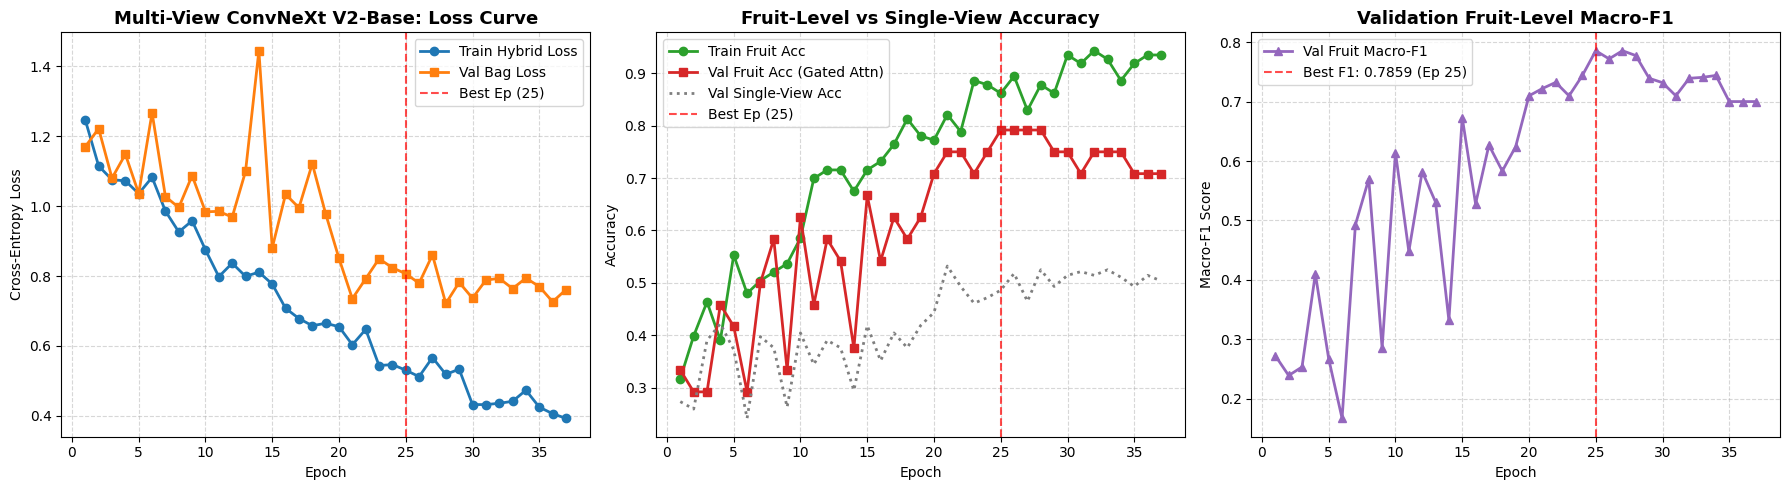

📊 Saved training curves to: /content/drive/MyDrive/durian-ripeness-cmkd/baselines/ConvNeXtV2-improve/results/convnextv2_multiview_training_curves.png
💾 Saved training history CSV to: /content/drive/MyDrive/durian-ripeness-cmkd/baselines/ConvNeXtV2-improve/results/training_history_multiview.csv


In [11]:
# 11. Plot Training & Validation Learning Curves and Save History to RESULTS_DIR
if len(history["train_loss"]) > 0:
    epochs_ran = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # 1. Loss Curve
    axes[0].plot(epochs_ran, history["train_loss"], label="Train Hybrid Loss", marker="o", linewidth=2, color="#1f77b4")
    axes[0].plot(epochs_ran, history["val_loss"], label="Val Bag Loss", marker="s", linewidth=2, color="#ff7f0e")
    axes[0].axvline(best_epoch, color="red", linestyle="--", alpha=0.7, label=f"Best Ep ({best_epoch})")
    axes[0].set_title("Multi-View ConvNeXt V2-Base: Loss Curve", fontsize=13, fontweight="bold")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Cross-Entropy Loss")
    axes[0].legend()
    axes[0].grid(True, linestyle="--", alpha=0.5)

    # 2. Fruit-Level & View-Level Accuracy Curves
    axes[1].plot(epochs_ran, history["train_fruit_acc"], label="Train Fruit Acc", marker="o", linewidth=2, color="#2ca02c")
    axes[1].plot(epochs_ran, history["val_fruit_acc"], label="Val Fruit Acc (Gated Attn)", marker="s", linewidth=2, color="#d62728")
    axes[1].plot(epochs_ran, history["val_view_acc"], label="Val Single-View Acc", linestyle=":", linewidth=2, color="#7f7f7f")
    axes[1].axvline(best_epoch, color="red", linestyle="--", alpha=0.7, label=f"Best Ep ({best_epoch})")
    axes[1].set_title("Fruit-Level vs Single-View Accuracy", fontsize=13, fontweight="bold")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()
    axes[1].grid(True, linestyle="--", alpha=0.5)

    # 3. Validation Fruit Macro-F1 Curve
    axes[2].plot(epochs_ran, history["val_fruit_f1"], label="Val Fruit Macro-F1", marker="^", linewidth=2, color="#9467bd")
    axes[2].axvline(best_epoch, color="red", linestyle="--", alpha=0.7, label=f"Best F1: {best_val_f1:.4f} (Ep {best_epoch})")
    axes[2].set_title("Validation Fruit-Level Macro-F1", fontsize=13, fontweight="bold")
    axes[2].set_xlabel("Epoch")
    axes[2].set_ylabel("Macro-F1 Score")
    axes[2].legend()
    axes[2].grid(True, linestyle="--", alpha=0.5)

    plt.tight_layout()
    curve_path = os.path.join(RESULTS_DIR, "convnextv2_multiview_training_curves.png")
    plt.savefig(curve_path, dpi=200)
    plt.show()
    print(f"📊 Saved training curves to: {curve_path}")

    df_hist = pd.DataFrame({
        "epoch": list(epochs_ran),
        "train_loss": history["train_loss"],
        "val_loss": history["val_loss"],
        "train_fruit_acc": history["train_fruit_acc"],
        "val_fruit_acc": history["val_fruit_acc"],
        "val_fruit_f1": history["val_fruit_f1"],
        "val_view_acc": history["val_view_acc"]
    })
    hist_csv_path = os.path.join(RESULTS_DIR, "training_history_multiview.csv")
    df_hist.to_csv(hist_csv_path, index=False)
    print(f"💾 Saved training history CSV to: {hist_csv_path}")


[*] 🔄 Loading best Multi-View ConvNeXt V2-Base checkpoint from: /content/drive/MyDrive/durian-ripeness-cmkd/baselines/ConvNeXtV2-improve/checkpoint/best_convnextv2_multiview.pth...
✅ Successfully loaded best Checkpoint at Epoch 25 (Val Loss: 0.8066 | Val Fruit Macro-F1: 0.7859)


Evaluating Multi-View Test Fruits:   0%|          | 0/12 [00:00<?, ?it/s]


🍈 MULTI-VIEW CONVNEXTV2 GATED ATTENTION FRUIT-LEVEL RESULTS (24 FRUITS | TTA=ON)
  • Test Bag Loss                        : 1.2071
  • Fruit-Level Accuracy (Gated Attention): 58.33 %
  • Fruit-Level Macro-F1 (Gated Attention): 0.5559

📋 [PER-CLASS FRUIT-LEVEL CLASSIFICATION REPORT (GATED ATTENTION)]
              precision    recall  f1-score   support

      Unripe     0.7000    0.8750    0.7778         8
        Ripe     0.4545    0.6250    0.5263         8
    Overripe     0.6667    0.2500    0.3636         8

    accuracy                         0.5833        24
   macro avg     0.6071    0.5833    0.5559        24
weighted avg     0.6071    0.5833    0.5559        24

🖼️ SINGLE-VIEW (IMAGE-LEVEL) AUXILIARY TEST RESULTS (298 IMAGES)
  • Image-Level Accuracy (Single-View)   : 38.26 %
  • Image-Level Macro-F1 (Single-View)   : 0.3805

💾 Saved Multi-View Gated Attention fruit predictions CSV at: /content/drive/MyDrive/durian-ripeness-cmkd/baselines/ConvNeXtV2-improve/results/test_fru

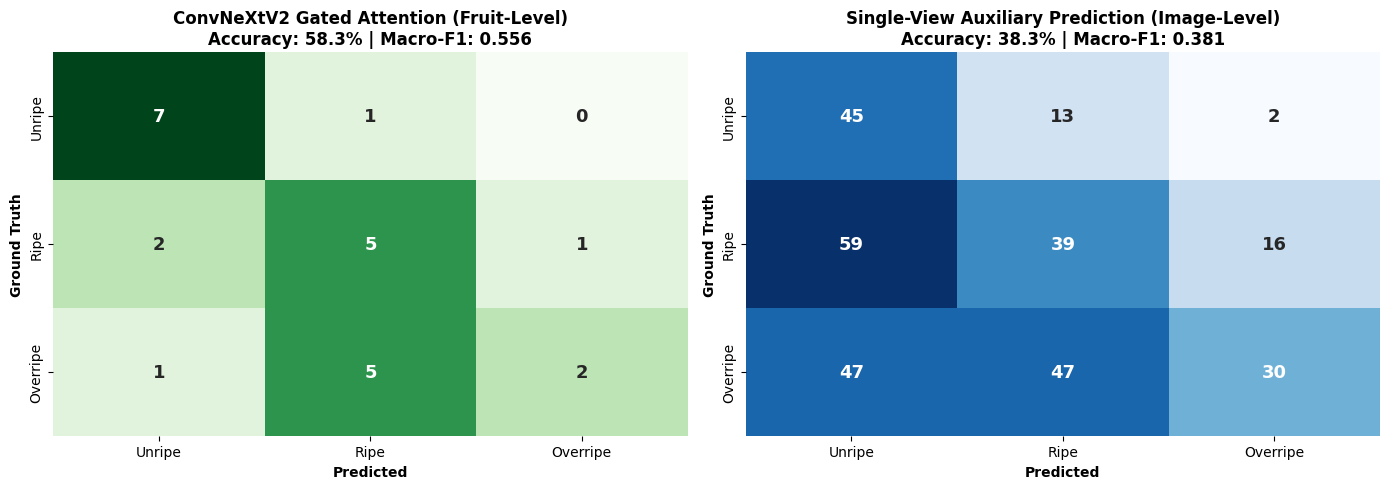

📊 Saved Multi-View confusion matrices at: /content/drive/MyDrive/durian-ripeness-cmkd/baselines/ConvNeXtV2-improve/results/test_confusion_matrices_multiview.png


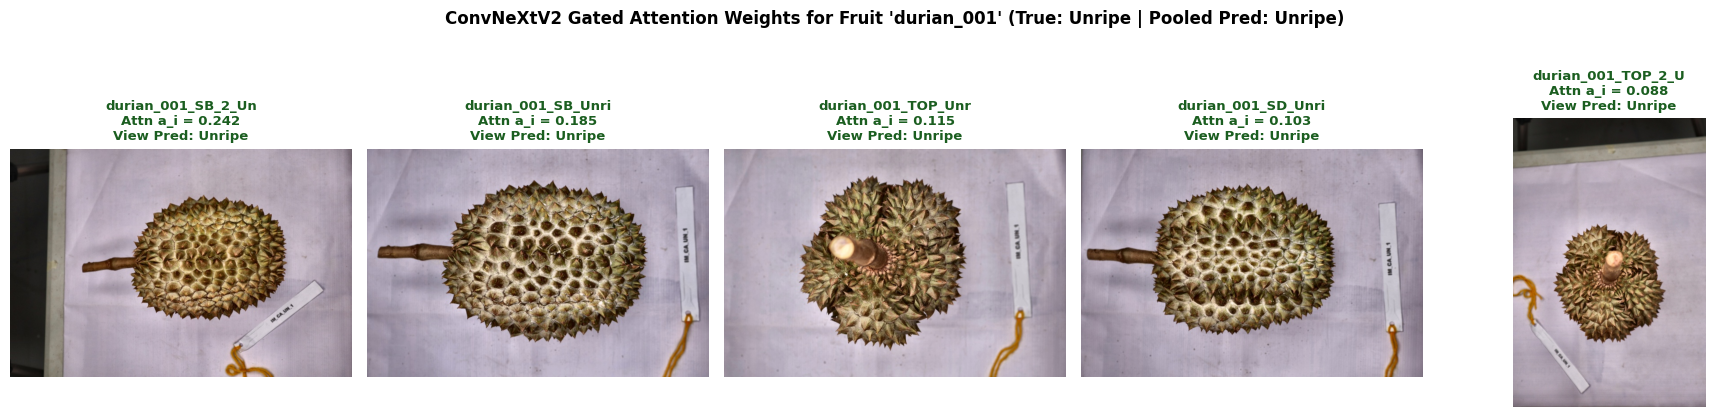

📊 Saved Gated Attention view-weight visualization at: /content/drive/MyDrive/durian-ripeness-cmkd/baselines/ConvNeXtV2-improve/results/test_gated_attention_views_sample.png


In [12]:
# 12. Comprehensive Test Evaluation: Gated Attention Fruit-Level Pooling, Per-View TTA & Attention Visualization
USE_TTA = True  # Multi-crop/flip Test-Time Augmentation on each view before Gated Attention Pooling

if os.path.isfile(BEST_CHECKPOINT_PATH):
    print(f"[*] 🔄 Loading best Multi-View ConvNeXt V2-Base checkpoint from: {BEST_CHECKPOINT_PATH}...")
    best_cp = torch.load(BEST_CHECKPOINT_PATH, map_location=DEVICE)
    model.load_state_dict(best_cp["model_state_dict"])
    print(f"✅ Successfully loaded best Checkpoint at Epoch {best_cp.get('epoch', 'N/A')} "
          f"(Val Loss: {best_cp.get('best_val_loss', 0.0):.4f} | Val Fruit Macro-F1: {best_cp.get('best_val_f1', 0.0):.4f})")
else:
    print("⚠️ Using current in-memory model weights.")

model.eval()

@torch.no_grad()
def extract_tta_view_embeddings(model: ConvNeXtV2MultiViewGatedAttention, flat_images: torch.Tensor, use_tta: bool = True) -> torch.Tensor:
    """Extract 256-d view embeddings f_i with optional 3-view TTA (Original + Horizontal Flip + 95% Central Zoom)."""
    f_orig = model.extract_view_embeddings(flat_images)
    if not use_tta:
        return f_orig

    # TTA 2: Horizontal Flip
    f_hflip = model.extract_view_embeddings(torch.flip(flat_images, dims=[3]))
    # TTA 3: Slight 95% Central Zoom
    pad = max(1, int(flat_images.shape[-1] * 0.025))
    cropped = flat_images[:, :, pad:-pad, pad:-pad]
    zoomed = F.interpolate(cropped, size=flat_images.shape[-2:], mode="bilinear", align_corners=False)
    f_zoom = model.extract_view_embeddings(zoomed)

    return 0.50 * f_orig + 0.30 * f_hflip + 0.20 * f_zoom

test_bag_loss = 0.0
total_test_fruits = 0

fruit_eval_records = []
image_eval_records = []

with torch.no_grad():
    for batch in tqdm(test_loader, desc="Evaluating Multi-View Test Fruits"):
        flat_images = batch["flat_images"].to(DEVICE)
        view_counts = batch["view_counts"]
        fruit_targets = batch["labels"].to(DEVICE)
        fruit_ids = batch["fruit_ids"]
        filenames_per_fruit = batch["filenames"]

        with torch.amp.autocast('cuda', enabled=(DEVICE.type == 'cuda')):
            # 1. Extract TTA-enhanced 256-d view embeddings f_i in R^{256}
            f_all_views = extract_tta_view_embeddings(model, flat_images, use_tta=USE_TTA)
            view_logits = model.classifier(f_all_views)
            view_probs = F.softmax(view_logits, dim=1).cpu().numpy()

            # 2. Pool each fruit's views via Lightweight Gated Attention: F_rgb = sum_i a_i f_i
            F_rgb_batch, attn_weights_list = model.pool_fruit_bags(f_all_views, view_counts)
            bag_logits = model.classifier(F_rgb_batch)
            bag_loss = criterion(bag_logits, fruit_targets)
            bag_probs = F.softmax(bag_logits, dim=1).cpu().numpy()

        batch_fruits = fruit_targets.size(0)
        test_bag_loss += bag_loss.item() * batch_fruits
        total_test_fruits += batch_fruits

        # Split view probabilities per fruit to record detailed image-level & attention weights
        idx_offset = 0
        for b_i in range(batch_fruits):
            n_v = view_counts[b_i]
            fid = fruit_ids[b_i]
            t_idx = int(fruit_targets[b_i].item())
            f_prob = bag_probs[b_i]
            f_pred = int(np.argmax(f_prob))
            attn_w = attn_weights_list[b_i].cpu().numpy()
            fnames = filenames_per_fruit[b_i]

            top_view_idx = int(np.argmax(attn_w))
            fruit_eval_records.append({
                "fruit_id": fid,
                "num_views": n_v,
                "true_label": RIPENESS_ORDER[t_idx],
                "pred_label": RIPENESS_ORDER[f_pred],
                "true_idx": t_idx,
                "pred_idx": f_pred,
                "prob_Unripe": float(f_prob[0]),
                "prob_Ripe": float(f_prob[1]),
                "prob_Overripe": float(f_prob[2]),
                "most_attended_view": fnames[top_view_idx],
                "max_attention_weight": float(attn_w[top_view_idx]),
                "min_attention_weight": float(np.min(attn_w)),
                "is_correct": bool(t_idx == f_pred)
            })

            for v_j in range(n_v):
                v_prob = view_probs[idx_offset + v_j]
                v_pred = int(np.argmax(v_prob))
                image_eval_records.append({
                    "filename": fnames[v_j],
                    "fruit_id": fid,
                    "true_label": RIPENESS_ORDER[t_idx],
                    "view_pred_label": RIPENESS_ORDER[v_pred],
                    "fruit_attn_pred_label": RIPENESS_ORDER[f_pred],
                    "true_idx": t_idx,
                    "view_pred_idx": v_pred,
                    "attention_weight": float(attn_w[v_j]),
                    "prob_Unripe": float(v_prob[0]),
                    "prob_Ripe": float(v_prob[1]),
                    "prob_Overripe": float(v_prob[2]),
                    "is_correct": bool(t_idx == v_pred)
                })
            idx_offset += n_v

test_bag_loss /= max(1, total_test_fruits)
df_fruit_results = pd.DataFrame(fruit_eval_records)
df_image_results = pd.DataFrame(image_eval_records)

# 1. FRUIT-LEVEL GATED ATTENTION EVALUATION RESULTS
fruit_y_true = df_fruit_results["true_idx"].values
fruit_y_pred = df_fruit_results["pred_idx"].values
fruit_acc = accuracy_score(fruit_y_true, fruit_y_pred)
fruit_macro_f1 = f1_score(fruit_y_true, fruit_y_pred, average="macro", zero_division=0)

# 2. IMAGE-LEVEL (SINGLE-VIEW) EVALUATION RESULTS
img_y_true = df_image_results["true_idx"].values
img_y_pred = df_image_results["view_pred_idx"].values
img_acc = accuracy_score(img_y_true, img_y_pred)
img_macro_f1 = f1_score(img_y_true, img_y_pred, average="macro", zero_division=0)

print("\n" + "="*74)
print(f"🍈 MULTI-VIEW CONVNEXTV2 GATED ATTENTION FRUIT-LEVEL RESULTS ({len(df_fruit_results)} FRUITS | TTA={'ON' if USE_TTA else 'OFF'})")
print("="*74)
print(f"  • Test Bag Loss                        : {test_bag_loss:.4f}")
print(f"  • Fruit-Level Accuracy (Gated Attention): {fruit_acc * 100:.2f} %")
print(f"  • Fruit-Level Macro-F1 (Gated Attention): {fruit_macro_f1:.4f}")
print("="*74)

fruit_report_str = classification_report(fruit_y_true, fruit_y_pred, target_names=RIPENESS_ORDER, digits=4, zero_division=0)
fruit_report_dict = classification_report(fruit_y_true, fruit_y_pred, target_names=RIPENESS_ORDER, digits=4, zero_division=0, output_dict=True)
print("\n📋 [PER-CLASS FRUIT-LEVEL CLASSIFICATION REPORT (GATED ATTENTION)]")
print(fruit_report_str)

print("="*74)
print(f"🖼️ SINGLE-VIEW (IMAGE-LEVEL) AUXILIARY TEST RESULTS ({len(df_image_results)} IMAGES)")
print("="*74)
print(f"  • Image-Level Accuracy (Single-View)   : {img_acc * 100:.2f} %")
print(f"  • Image-Level Macro-F1 (Single-View)   : {img_macro_f1:.4f}")
print("="*74 + "\n")

# Save detailed CSVs and JSON summary in RESULTS_DIR
csv_fruit_path = os.path.join(RESULTS_DIR, "test_fruit_level_gated_attention.csv")
df_fruit_results.to_csv(csv_fruit_path, index=False, encoding="utf-8")
print(f"💾 Saved Multi-View Gated Attention fruit predictions CSV at: {csv_fruit_path}")

csv_img_path = os.path.join(RESULTS_DIR, "test_view_level_attention_weights.csv")
df_image_results.to_csv(csv_img_path, index=False, encoding="utf-8")
print(f"💾 Saved per-view predictions & Gated Attention weights CSV at: {csv_img_path}")

metrics_summary = {
    "model": "Multi-View ConvNeXt V2-Base (convnextv2_base.fcmae_ft_in1k) + 256-d Projection + Lightweight Gated Attention (Ilse et al., D=128)",
    "image_size": IMAGE_SIZE,
    "backbone_dim": 1024,
    "embed_dim": 256,
    "attn_hidden_dim": 128,
    "use_tta": USE_TTA,
    "best_epoch": int(best_cp.get("epoch", best_epoch)) if 'best_cp' in locals() else int(best_epoch),
    "test_bag_loss": float(test_bag_loss),
    "fruit_level_accuracy": float(fruit_acc),
    "fruit_level_macro_f1": float(fruit_macro_f1),
    "image_level_accuracy": float(img_acc),
    "image_level_macro_f1": float(img_macro_f1),
    "total_test_fruits": int(len(df_fruit_results)),
    "total_test_images": int(len(df_image_results)),
    "fruit_classification_report": fruit_report_dict,
    "timestamp": time.strftime("%Y-%m-%d %H:%M:%S")
}
json_summary_path = os.path.join(RESULTS_DIR, "test_metrics_summary_multiview.json")
with open(json_summary_path, "w", encoding="utf-8") as f:
    json.dump(metrics_summary, f, indent=2, ensure_ascii=False)
print(f"💾 Saved Multi-View test metrics summary JSON at: {json_summary_path}")

# 3. PLOT SIDE-BY-SIDE CONFUSION MATRICES (FRUIT-LEVEL GATED ATTENTION vs SINGLE-VIEW)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cm_fruit = confusion_matrix(fruit_y_true, fruit_y_pred)
sns.heatmap(cm_fruit, annot=True, fmt="d", cmap="Greens", ax=axes[0],
            xticklabels=RIPENESS_ORDER, yticklabels=RIPENESS_ORDER, cbar=False,
            annot_kws={"size": 13, "weight": "bold"})
axes[0].set_title(f"ConvNeXtV2 Gated Attention (Fruit-Level)\nAccuracy: {fruit_acc*100:.1f}% | Macro-F1: {fruit_macro_f1:.3f}", fontweight="bold")
axes[0].set_xlabel("Predicted", fontweight="bold")
axes[0].set_ylabel("Ground Truth", fontweight="bold")

cm_img = confusion_matrix(img_y_true, img_y_pred)
sns.heatmap(cm_img, annot=True, fmt="d", cmap="Blues", ax=axes[1],
            xticklabels=RIPENESS_ORDER, yticklabels=RIPENESS_ORDER, cbar=False,
            annot_kws={"size": 13, "weight": "bold"})
axes[1].set_title(f"Single-View Auxiliary Prediction (Image-Level)\nAccuracy: {img_acc*100:.1f}% | Macro-F1: {img_macro_f1:.3f}", fontweight="bold")
axes[1].set_xlabel("Predicted", fontweight="bold")
axes[1].set_ylabel("Ground Truth", fontweight="bold")

plt.tight_layout()
cm_fig_path = os.path.join(RESULTS_DIR, "test_confusion_matrices_multiview.png")
plt.savefig(cm_fig_path, dpi=200)
plt.show()
print(f"📊 Saved Multi-View confusion matrices at: {cm_fig_path}")

# 4. VISUALIZE GATED ATTENTION WEIGHTS ACROSS VIEWS OF A SAMPLE TEST FRUIT
if len(df_fruit_results) > 0:
    sample_fid = df_fruit_results.iloc[0]["fruit_id"]
    sample_views_df = df_image_results[df_image_results["fruit_id"] == sample_fid].sort_values("attention_weight", ascending=False)
    top_k_views = sample_views_df.head(min(5, len(sample_views_df)))

    fig, axes = plt.subplots(1, len(top_k_views), figsize=(3.6 * len(top_k_views), 4.0))
    if len(top_k_views) == 1:
        axes = [axes]
    for ax, (_, row) in zip(axes, top_k_views.iterrows()):
        img_path = None
        for sp_item in image_splits["test"]:
            if sp_item["filename"] == row["filename"]:
                img_path = sp_item["filepath"]
                break
        if img_path and os.path.isfile(img_path):
            disp_img = cv2.imread(img_path)
            disp_img = cv2.cvtColor(disp_img, cv2.COLOR_BGR2RGB)
            ax.imshow(disp_img)
        ax.set_title(f"{row['filename'][:18]}\nAttn a_i = {row['attention_weight']:.3f}\nView Pred: {row['view_pred_label']}",
                     fontsize=9.5, fontweight="bold", color="#1b5e20" if row["is_correct"] else "#b71c1c")
        ax.axis("off")
    f_row = df_fruit_results.iloc[0]
    plt.suptitle(
        f"ConvNeXtV2 Gated Attention Weights for Fruit '{sample_fid}' (True: {f_row['true_label']} | Pooled Pred: {f_row['pred_label']})",
        fontweight="bold", y=1.03
    )
    plt.tight_layout()
    attn_fig_path = os.path.join(RESULTS_DIR, "test_gated_attention_views_sample.png")
    plt.savefig(attn_fig_path, dpi=200, bbox_inches="tight")
    plt.show()
    print(f"📊 Saved Gated Attention view-weight visualization at: {attn_fig_path}")


## 🎯 Summary of Saved Checkpoints & Multi-View Test Artifacts

1. **Checkpoints (`/content/drive/MyDrive/durian-ripeness-cmkd/baselines/ConvNeXtV2/checkpoint`):**
   - **`convnextv2_pretrained_raw_weights.pth`**: Cached raw FCMAE ImageNet-1K pretrained weights (avoids re-downloading 355MB on subsequent runs).
   - **`best_convnextv2_multiview.pth`**: Best overall Multi-View Gated Attention checkpoint selected by maximum Fruit-Level Validation Macro-F1.
   - **`last_convnextv2_multiview.pth`**: Latest epoch checkpoint for seamless training resumption.
   - **`checkpoint_convnextv2_multiview_epoch_XX.pth`**: Periodic snapshots saved every 5 epochs.
   - **`convnextv2_multiview_backbone_256d.pth`**: Clean $256\text{-d}$ Multi-View Visual Extractor (`backbone` + `1024->256 projection` + `gated_attention`) ready for Cross-Modal Knowledge Distillation (CMKD).
2. **Test Results (`/content/drive/MyDrive/durian-ripeness-cmkd/baselines/ConvNeXtV2/results`):**
   - **`test_fruit_level_gated_attention.csv`**: Fruit-level predictions, probabilities, and highest-attended view per fruit.
   - **`test_view_level_attention_weights.csv`**: Per-image class probabilities and learned Gated Attention weight $a_i$ for each view.
   - **`test_metrics_summary_multiview.json`**: Complete JSON report of Fruit-level & Image-level Accuracy, Macro-F1, and per-class metrics.
   - **`convnextv2_multiview_training_curves.png` & `training_history_multiview.csv`**: Training/validation loss, fruit-level accuracy, and Macro-F1 curves.
   - **`test_confusion_matrices_multiview.png` & `test_gated_attention_views_sample.png`**: Visual evaluation and Gated Attention interpretability analysis.